# Predicting Himalayan Expedition Success
CSC61304 Machine Learning and Intelligent Systems - individual assignment

Name: Kritak Aryal (0382309)

**Question:** before an expedition starts, can we predict if it will reach the summit?

**Models:** Logistic Regression (baseline), Random Forest, XGBoost

**Data:** Himalayan Database, shared by TidyTuesday (22 Sep 2020). Download `expeditions.csv` and `peaks.csv` from
https://github.com/rfordatascience/tidytuesday/tree/main/data/2020/2020-09-22 and keep them in the same folder as this notebook.

# Importing libraries

In [1]:
import pickle
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, confusion_matrix, classification_report)

sns.set_theme(style="whitegrid")

# Load the data

In [2]:
df = pd.read_csv("expeditions.csv")
peaks = pd.read_csv("peaks.csv")
print(df.shape)
print(peaks.shape)
df.head()

(10364, 16)
(468, 8)


,expedition_id,peak_id,peak_name,year,season,basecamp_date,highpoint_date,termination_date,termination_reason,highpoint_metres,members,member_deaths,hired_staff,hired_staff_deaths,oxygen_used,trekking_agency
0,ANN260101,ANN2,Annapurna II,1960,Spring,1960-03-15,1960-05-17,NaN,Success (main peak),7937.0,10,0,9,0,True,NaN
1,ANN269301,ANN2,Annapurna II,1969,Autumn,1969-09-25,1969-10-22,1969-10-26,Success (main peak),7937.0,10,0,0,0,False,NaN
2,ANN273101,ANN2,Annapurna II,1973,Spring,1973-03-16,1973-05-06,NaN,Success (main peak),7937.0,6,0,8,0,False,NaN
3,ANN278301,ANN2,Annapurna II,1978,Autumn,1978-09-08,1978-10-02,1978-10-05,"Bad weather (storms, high winds)",7000.0,2,0,0,0,False,NaN
4,ANN279301,ANN2,Annapurna II,1979,Autumn,NaN,1979-10-18,1979-10-20,"Bad weather (storms, high winds)",7160.0,3,0,0,0,False,NaN


In [3]:
df.columns

Index(['expedition_id', 'peak_id', 'peak_name', 'year', 'season',
       'basecamp_date', 'highpoint_date', 'termination_date',
       'termination_reason', 'highpoint_metres', 'members', 'member_deaths',
       'hired_staff', 'hired_staff_deaths', 'oxygen_used', 'trekking_agency'],
      dtype='str')

In [4]:
df.isnull().sum()

expedition_id            0
peak_id                  0
peak_name                1
year                     0
season                   0
basecamp_date         1095
highpoint_date         650
termination_date      2380
termination_reason       0
highpoint_metres       414
members                  0
member_deaths            0
hired_staff              0
hired_staff_deaths       0
oxygen_used              0
trekking_agency       1710
dtype: int64

# Join the peak height
expeditions.csv does not have the height of the peak, peaks.csv does. Join them using peak_id.

In [5]:
peaks_small = peaks[["peak_id", "height_metres"]]
df = df.merge(peaks_small, on="peak_id", how="left")
df.shape

(10364, 17)

# Making the target (success or not)
The column `termination_reason` tells how the expedition ended. Success = 1, any failure = 0.

In [6]:
df["termination_reason"].value_counts()

termination_reason
Success (main peak)                                                             5581
Bad weather (storms, high winds)                                                1307
Bad conditions (deep snow, avalanching, falling ice, or rock)                   1097
Illness, AMS, exhaustion, or frostbite                                           458
Route technically too difficult, lack of experience, strength, or motivation     438
Other                                                                            320
Accident (death or serious injury)                                               299
Did not attempt climb                                                            233
Lack (or loss) of supplies or equipment                                          220
Success (subpeak)                                                                126
Unknown                                                                           96
Lack of time                                  

In [7]:
# these rows are not a real attempt (or the summit is unclear), so remove them
remove = ["Did not attempt climb", "Attempt rumoured", "Unknown", "Did not reach base camp", "Success (subpeak)"]
df = df[~df["termination_reason"].isin(remove)]

# season Unknown is only 2 rows
df = df[df["season"] != "Unknown"]

df["success"] = df["termination_reason"].apply(lambda x: 1 if x in ["Success (main peak)", "Success (claimed)"] else 0)
print(df.shape)
df["success"].value_counts()

(9832, 18)


success
1    5600
0    4232
Name: count, dtype: int64

# Features I will use
Only things known **before** the expedition starts. I do not use `highpoint_metres`, `termination_date`, `termination_reason`, `member_deaths` because they are only known after the expedition (that would be cheating / data leakage).

In [8]:
df["has_agency"] = df["trekking_agency"].notna().astype(int)   # 1 if a trekking agency is written
df["oxygen_used"] = df["oxygen_used"].astype(int)

features = ["year", "season", "members", "hired_staff", "oxygen_used", "has_agency", "height_metres"]
data = df[features + ["success"]]
data.head()

,year,season,members,hired_staff,oxygen_used,has_agency,height_metres,success
0,1960,Spring,10,9,1,0,7937.0,1
1,1969,Autumn,10,0,0,0,7937.0,1
2,1973,Spring,6,8,0,0,7937.0,1
3,1978,Autumn,2,0,0,0,7937.0,0
4,1979,Autumn,3,0,0,0,7937.0,0


In [9]:
data.isnull().sum()

year             0
season           0
members          0
hired_staff      0
oxygen_used      0
has_agency       0
height_metres    1
success          0
dtype: int64

# EDA

success rate: 0.57


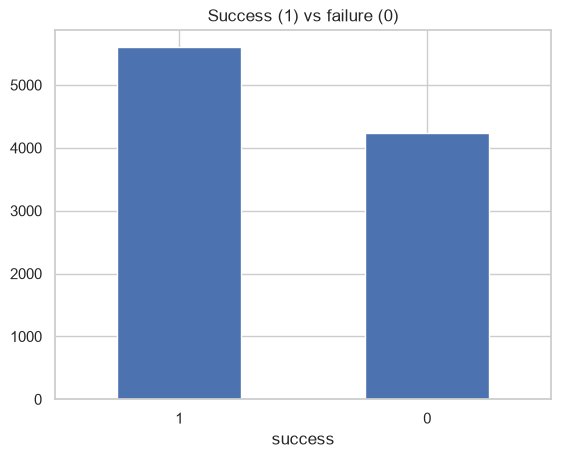

In [10]:
print("success rate:", data["success"].mean().round(3))
data["success"].value_counts().plot(kind="bar")
plt.title("Success (1) vs failure (0)")
plt.xticks(rotation=0)
plt.show()

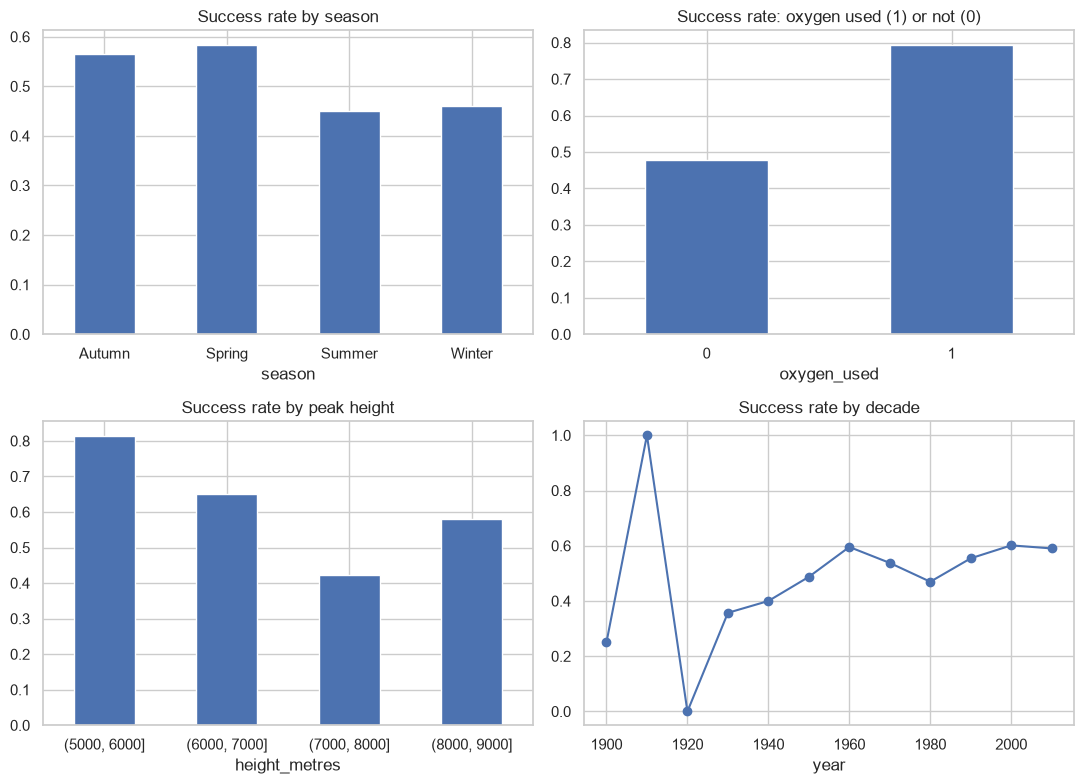

In [11]:
fig, ax = plt.subplots(2, 2, figsize=(11, 8))

data.groupby("season")["success"].mean().plot(kind="bar", ax=ax[0, 0], rot=0)
ax[0, 0].set_title("Success rate by season")

data.groupby("oxygen_used")["success"].mean().plot(kind="bar", ax=ax[0, 1], rot=0)
ax[0, 1].set_title("Success rate: oxygen used (1) or not (0)")

data.groupby(pd.cut(data["height_metres"], [5000, 6000, 7000, 8000, 9000]))["success"].mean().plot(kind="bar", ax=ax[1, 0], rot=0)
ax[1, 0].set_title("Success rate by peak height")

data.groupby((data["year"] // 10) * 10)["success"].mean().plot(marker="o", ax=ax[1, 1])
ax[1, 1].set_title("Success rate by decade")

plt.tight_layout()
plt.savefig("eda_success_rates.png")
plt.show()

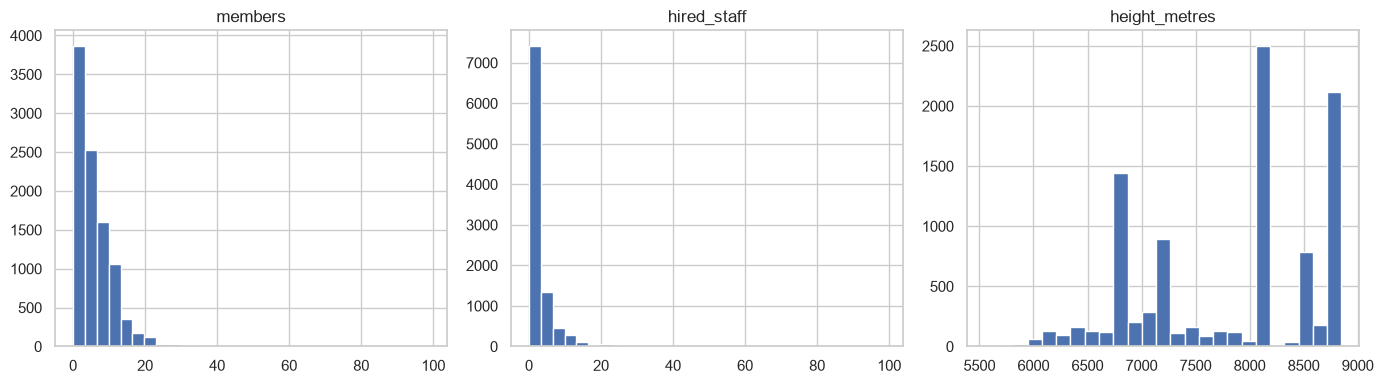

In [12]:
fig, ax = plt.subplots(1, 3, figsize=(14, 4))
ax[0].hist(data["members"], bins=30)
ax[0].set_title("members")
ax[1].hist(data["hired_staff"], bins=30)
ax[1].set_title("hired_staff")
ax[2].hist(data["height_metres"].dropna(), bins=25)
ax[2].set_title("height_metres")
plt.tight_layout()
plt.show()

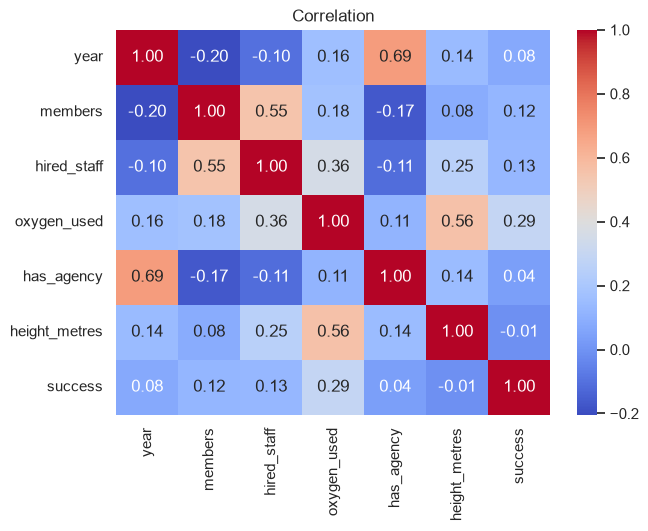

In [13]:
plt.figure(figsize=(7, 5))
sns.heatmap(data.drop(columns="season").corr(), annot=True, fmt=".2f", cmap="coolwarm")
plt.title("Correlation")
plt.show()

**What I see (EDA):**
- **Classes:** 5600 success vs 4232 failure (57% / 43%). Fairly balanced, so no need for resampling. But a model that always says "success" is already right 57-59% of the time, so my accuracy must be compared with that number.
- **Oxygen is the strongest signal.** Success is 79% with oxygen vs 48% without. It also has the highest correlation with success (0.29).
- **Height is tricky.** Its correlation with success is about 0 (-0.01), but the bar chart is not a straight line: 81% (5-6k m, only 43 expeditions), 65% (6-7k), 42% (7-8k), 58% (8-9k). The jump back up above 8000 m is because about half of those expeditions use oxygen (2-5% below 8000 m). Above 8000 m: 37% success without oxygen, 80% with oxygen. So height only makes sense together with oxygen.
- **Season:** spring 58%, autumn 57%, summer 45%, winter 46%. Summer (89) and winter (306) have very few expeditions, so those two numbers are weak evidence.
- **Team size:** bigger teams and more hired staff do better (members 1 -> 50%, 13+ -> 71%; staff 0 -> 49%, 9+ -> 74%). members and hired_staff are related to each other (0.55).
- **Time:** success rate went from about 0.4 before 1960 to about 0.6 since 2000. Decades before 1950 have fewer than 30 expeditions, so the spikes in the line plot are just noise.
- **has_agency:** correlation with success is only 0.04, but 0.69 with year. Agencies are written in 0% of records before 1970 and 98% after 2000, so it mostly tells "how recent the record is".
- **Shapes:** members and hired_staff are right-skewed (max 99, only 2% above 20, 34% have no staff). Height has spikes near 6800, 8100 and 8800 m (the famous peaks).

# Before preprocessing: what is going on and what we decide
**What is going on.** The data has about 10,000 expeditions. The target (success) is almost balanced. No single column explains success well: the best linear correlation is only 0.29 (oxygen). The two most useful columns (oxygen and height) are tangled together, because climbers use oxygen mainly on the 8000 m+ peaks. Also, the old records (before 1970) look very different from the recent ones (no agency, few oxygen users).

**Decisions that come from the EDA:**
1. **Keep the 7 columns** (year, season, members, hired_staff, oxygen_used, has_agency, height_metres). Each one is known before the expedition starts. The checks below show oxygen and height matter most, has_agency adds almost nothing (see the check cells after feature importance).
2. **Use tree models (Random Forest, XGBoost) and keep Logistic Regression as a baseline.** Linear correlations are weak (max 0.29), height is not a straight line, and oxygen + height work together. Trees can handle that, a straight-line model cannot.
3. **No outlier removal and no resampling.** Trees do not care about big values, and classes are 57/43.
4. **Scale only for Logistic Regression.** Trees do not need it.
5. **Fill missing height with the train median.** Only 1 row is missing after the join, so this choice hardly matters.
6. **Split by year, not randomly** (train up to 2009, test 2010+). The model will be used to predict future expeditions, so we test it on future expeditions. Be careful: the test years are different (oxygen use 26% -> 37%, agency 77% -> 98%), see the table in the error analysis.
7. **Judge with accuracy, F1 and ROC-AUC**, because accuracy alone can hide which mistakes the model makes (shown after the results table).

Run the small check cells below to see the numbers behind these decisions.

In [14]:
# how many expeditions are in each group? (a success rate means little if the group is tiny)
print(data["season"].value_counts())
print()
print(pd.cut(data["height_metres"], [5000, 6000, 7000, 8000, 9000]).value_counts().sort_index())
print()
print(data["year"].floordiv(10).mul(10).value_counts().sort_index())

season
Autumn    4754
Spring    4683
Winter     306
Summer      89
Name: count, dtype: int64

height_metres
(5000, 6000]      43
(6000, 7000]    2341
(7000, 8000]    1809
(8000, 9000]    5638
Name: count, dtype: int64

year
1900       4
1910       1
1920       8
1930      28
1940      10
1950     119
1960     136
1970     331
1980    1122
1990    1668
2000    3093
2010    3312
Name: count, dtype: int64


In [15]:
# height and oxygen together: success rate and number of expeditions
height_group = pd.cut(data["height_metres"], [5000, 6000, 7000, 8000, 9000])
print(data.groupby([height_group, "oxygen_used"])["success"].agg(["mean", "size"]).round(3))

                            mean  size
height_metres oxygen_used             
(5000, 6000]  0            0.795    39
              1            1.000     4
(6000, 7000]  0            0.652  2298
              1            0.558    43
(7000, 8000]  0            0.415  1721
              1            0.591    88
(8000, 9000]  0            0.370  2891
              1            0.803  2747


In [16]:
# has_agency is it real information or just "recent records"?
print(data.groupby((data["year"] // 10) * 10)["has_agency"].mean().round(2))

year
1900    0.00
1910    0.00
1920    0.00
1930    0.00
1940    0.00
1950    0.00
1960    0.00
1970    0.03
1980    0.41
1990    0.93
2000    0.98
2010    0.98
Name: has_agency, dtype: float64


**Reading the checks above:** season Summer has only 89 expeditions and Winter 306, so their success rates are not reliable. Before 1950 there are fewer than 30 expeditions per decade. Above 8000 m, success without oxygen is 37% but with oxygen 80%, so height and oxygen must be read together. has_agency is 0% before 1970 and 98% after 2000, which means it follows the year more than it follows success.

# Preprocessing
1. one hot encode `season`
2. split by time (train = up to 2009, test = 2010 onwards). A random split would let the model see future expeditions while training, so I split by year.
3. fill missing height with the **train** median (so nothing from test leaks in)
4. scale the numbers (needed for Logistic Regression only, trees do not care)

In [17]:
data = pd.get_dummies(data, columns=["season"], drop_first=True)
data.head()

,year,members,hired_staff,oxygen_used,has_agency,height_metres,success,season_Spring,season_Summer,season_Winter
0,1960,10,9,1,0,7937.0,1,True,False,False
1,1969,10,0,0,0,7937.0,1,False,False,False
2,1973,6,8,0,0,7937.0,1,True,False,False
3,1978,2,0,0,0,7937.0,0,False,False,False
4,1979,3,0,0,0,7937.0,0,False,False,False


In [18]:
train = data[data["year"] <= 2009]
test = data[data["year"] >= 2010]

X_train = train.drop(columns="success")
y_train = train["success"]
X_test = test.drop(columns="success")
y_test = test["success"]

print("Train:", X_train.shape, "| Test:", X_test.shape)
print("success rate train:", y_train.mean().round(3))
print("success rate test:", y_test.mean().round(3))

Train: (6520, 9) | Test: (3312, 9)
success rate train: 0.559
success rate test: 0.59


In [19]:
train_median = X_train["height_metres"].median()
X_train["height_metres"] = X_train["height_metres"].fillna(train_median)
X_test["height_metres"] = X_test["height_metres"].fillna(train_median)
print("Missing left:", X_train.isnull().sum().sum() + X_test.isnull().sum().sum())

Missing left: 0


In [20]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Training the 3 models (default settings)

In [21]:
lr = LogisticRegression(max_iter=1000)
lr.fit(X_train_scaled, y_train)

rf = RandomForestClassifier(n_estimators=200, random_state=42)
rf.fit(X_train, y_train)

xgb = XGBClassifier(n_estimators=200, random_state=42)
xgb.fit(X_train, y_train)

,"base_score base_score: typing.Union[float, typing.List[float], NoneType]The initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.Optional[typing.List[xgboost.callback.TrainingCallback]]List of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API <callback_api>`... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: typing.Optional[float]Subsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: typing.Optional[float]Subsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: typing.Optional[float]Subsample ratio of columns when constructing each tree.,None
,"device device: typing.Optional[str].. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: typing.Optional[int].. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",None
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,True
,"eval_metric eval_metric: typing.Union[str, typing.List[typing.Union[str, typing.Callable]], typing.Callable, NoneType].. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets import load_diabetes from sklearn.metrics import mean_absolute_error X, y = load_diabetes(return_X_y=True) reg = xgb.XGBRegressor( tree_method=""hist"", eval_metric=mean_absolute_error, ) reg.fit(X, y, eval_set=[(X, y)])",None
,feature_types feature_types: typing.Optional[typing.Sequence[str]].. versionadded:: 1.7.0Used for specifying feature types without constructing a dataframe. Seethe :py:class:`DMatrix` for details.,None


In [22]:
def show_scores(name, y_true, y_pred, y_prob):
    print(name)
    print(f"Accuracy: {accuracy_score(y_true, y_pred):.4f}")
    print(f"Precision: {precision_score(y_true, y_pred):.4f}")
    print(f"Recall: {recall_score(y_true, y_pred):.4f}")
    print(f"F1: {f1_score(y_true, y_pred):.4f}")
    print(f"ROC-AUC: {roc_auc_score(y_true, y_prob):.4f}")
    print()

show_scores("Logistic Regression", y_test, lr.predict(X_test_scaled), lr.predict_proba(X_test_scaled)[:, 1])
show_scores("Random Forest", y_test, rf.predict(X_test), rf.predict_proba(X_test)[:, 1])
show_scores("XGBoost", y_test, xgb.predict(X_test), xgb.predict_proba(X_test)[:, 1])

Logistic Regression
Accuracy: 0.7065
Precision: 0.6954
Recall: 0.8946
F1: 0.7826
ROC-AUC: 0.7727

Random Forest
Accuracy: 0.7083
Precision: 0.7193
Recall: 0.8297
F1: 0.7705
ROC-AUC: 0.7453

XGBoost
Accuracy: 0.7126
Precision: 0.7260
Recall: 0.8240
F1: 0.7719
ROC-AUC: 0.7617



# Hyperparameter tuning
GridSearchCV tries every combination in the grid with 5-fold cross validation on the **train** set only. I use ROC-AUC to pick the best one.

The rows in the file are in order of peak/time, so I shuffle before making the 5 folds (shuffle=True). Without this, each fold would be a different era and the CV score becomes misleading.

In [23]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

rf_grid = {
    "n_estimators": [100, 300],
    "max_depth": [5, 10, None],
    "min_samples_leaf": [1, 5]
}
rf_search = GridSearchCV(RandomForestClassifier(random_state=42), rf_grid, scoring="roc_auc", cv=cv, n_jobs=-1)
rf_search.fit(X_train, y_train)

print("Best RF settings:", rf_search.best_params_)
print(f"Best CV ROC-AUC: {rf_search.best_score_:.4f}")

Best RF settings: {'max_depth': 10, 'min_samples_leaf': 1, 'n_estimators': 300}
Best CV ROC-AUC: 0.7526


In [24]:
xgb_grid = {
    "n_estimators": [100, 300],
    "max_depth": [3, 5],
    "learning_rate": [0.05, 0.1]
}
xgb_search = GridSearchCV(XGBClassifier(random_state=42), xgb_grid, scoring="roc_auc", cv=cv, n_jobs=-1)
xgb_search.fit(X_train, y_train)

print("Best XGB settings:", xgb_search.best_params_)
print(f"Best CV ROC-AUC: {xgb_search.best_score_:.4f}")

Best XGB settings: {'learning_rate': 0.05, 'max_depth': 5, 'n_estimators': 300}
Best CV ROC-AUC: 0.7571


In [25]:
lr_grid = {"C": [0.01, 0.1, 1, 10]}
lr_search = GridSearchCV(LogisticRegression(max_iter=1000), lr_grid, scoring="roc_auc", cv=cv)
lr_search.fit(X_train_scaled, y_train)

print("Best LR settings:", lr_search.best_params_)
print(f"Best CV ROC-AUC: {lr_search.best_score_:.4f}")

Best LR settings: {'C': 10}
Best CV ROC-AUC: 0.6873


# Results on the test set (after tuning)

In [26]:
lr_best = lr_search.best_estimator_
rf_best = rf_search.best_estimator_
xgb_best = xgb_search.best_estimator_

show_scores("Logistic Regression (tuned)", y_test, lr_best.predict(X_test_scaled), lr_best.predict_proba(X_test_scaled)[:, 1])
show_scores("Random Forest (tuned)", y_test, rf_best.predict(X_test), rf_best.predict_proba(X_test)[:, 1])
show_scores("XGBoost (tuned)", y_test, xgb_best.predict(X_test), xgb_best.predict_proba(X_test)[:, 1])

Logistic Regression (tuned)
Accuracy: 0.7065
Precision: 0.6954
Recall: 0.8946
F1: 0.7826
ROC-AUC: 0.7727

Random Forest (tuned)
Accuracy: 0.7325
Precision: 0.7539
Recall: 0.8118
F1: 0.7818
ROC-AUC: 0.8058

XGBoost (tuned)
Accuracy: 0.7337
Precision: 0.7334
Recall: 0.8624
F1: 0.7927
ROC-AUC: 0.8062



In [27]:
# one table for the report
results = pd.DataFrame({
    "Model": ["Logistic Regression", "Random Forest", "XGBoost"],
    "Accuracy": [accuracy_score(y_test, lr_best.predict(X_test_scaled)),
                 accuracy_score(y_test, rf_best.predict(X_test)),
                 accuracy_score(y_test, xgb_best.predict(X_test))],
    "F1": [f1_score(y_test, lr_best.predict(X_test_scaled)),
           f1_score(y_test, rf_best.predict(X_test)),
           f1_score(y_test, xgb_best.predict(X_test))],
    "ROC-AUC": [roc_auc_score(y_test, lr_best.predict_proba(X_test_scaled)[:, 1]),
                roc_auc_score(y_test, rf_best.predict_proba(X_test)[:, 1]),
                roc_auc_score(y_test, xgb_best.predict_proba(X_test)[:, 1])]
}).round(4)
results

,Model,Accuracy,F1,ROC-AUC
0,Logistic Regression,0.7065,0.7826,0.7727
1,Random Forest,0.7325,0.7818,0.8058
2,XGBoost,0.7337,0.7927,0.8062


In [28]:
print("Random Forest")
print(classification_report(y_test, rf_best.predict(X_test)))
print("XGBoost")
print(classification_report(y_test, xgb_best.predict(X_test)))

Random Forest
              precision    recall  f1-score   support

           0       0.70      0.62      0.65      1357
           1       0.75      0.81      0.78      1955

    accuracy                           0.73      3312
   macro avg       0.72      0.72      0.72      3312
weighted avg       0.73      0.73      0.73      3312

XGBoost
              precision    recall  f1-score   support

           0       0.73      0.55      0.63      1357
           1       0.73      0.86      0.79      1955

    accuracy                           0.73      3312
   macro avg       0.73      0.71      0.71      3312
weighted avg       0.73      0.73      0.73      3312



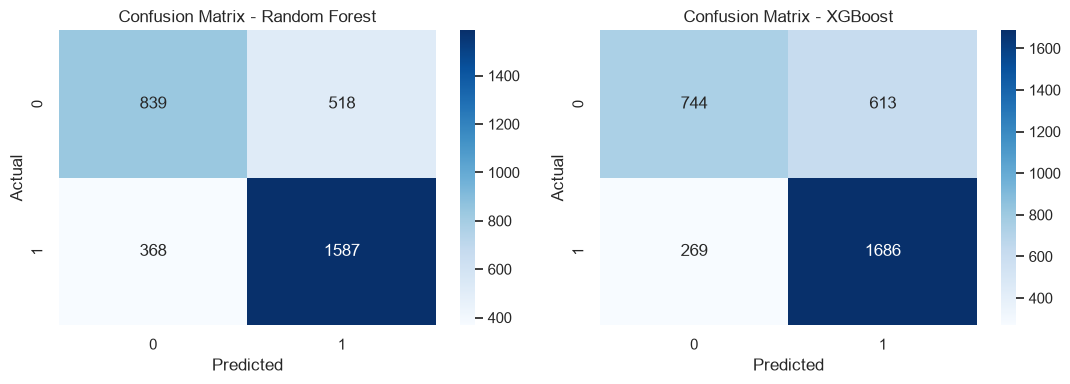

In [29]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
for a, name, model in [(ax[0], "Random Forest", rf_best), (ax[1], "XGBoost", xgb_best)]:
    cm = confusion_matrix(y_test, model.predict(X_test))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", ax=a)
    a.set_title(f"Confusion Matrix - {name}")
    a.set_xlabel("Predicted")
    a.set_ylabel("Actual")
plt.tight_layout()
plt.savefig("confusion_matrices.png")
plt.show()

# Which features matter?

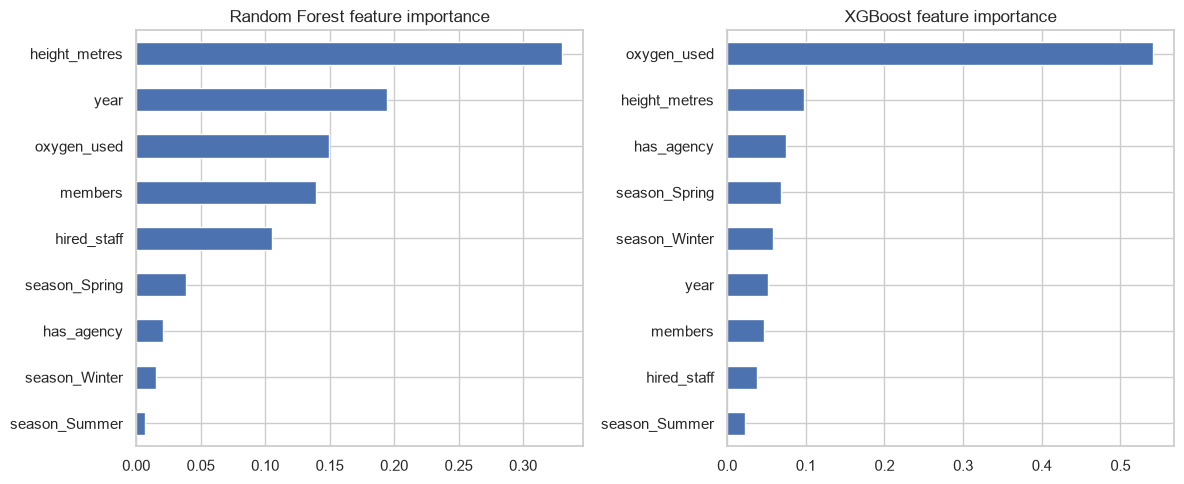

In [30]:
rf_importance = pd.Series(rf_best.feature_importances_, index=X_train.columns).sort_values()
xgb_importance = pd.Series(xgb_best.feature_importances_, index=X_train.columns).sort_values()

fig, ax = plt.subplots(1, 2, figsize=(12, 5))
rf_importance.plot(kind="barh", ax=ax[0])
ax[0].set_title("Random Forest feature importance")
xgb_importance.plot(kind="barh", ax=ax[1])
ax[1].set_title("XGBoost feature importance")
plt.tight_layout()
plt.savefig("feature_importance.png")
plt.show()

**Reading the two charts above:** Random Forest puts height_metres first, XGBoost puts oxygen_used first. They disagree because built-in importance is not a precise measure (it favours columns with many different values). The check below, which removes one feature at a time, is the fairer test.

# Checks behind the decisions
These small cells give the numbers I use to explain why I chose the columns, the split and the models.

In [31]:
# remove one feature at a time and see how much the test ROC-AUC drops
# (same Random Forest settings that GridSearchCV found)
base_auc = roc_auc_score(y_test, rf_best.predict_proba(X_test)[:, 1])
print(f"All features: {base_auc:.4f}")

groups = {
    "year": ["year"],
    "members": ["members"],
    "hired_staff": ["hired_staff"],
    "oxygen_used": ["oxygen_used"],
    "has_agency": ["has_agency"],
    "height_metres": ["height_metres"],
    "season": ["season_Spring", "season_Summer", "season_Winter"],
}

for name, cols in groups.items():
    m = RandomForestClassifier(**rf_search.best_params_, random_state=42)
    m.fit(X_train.drop(columns=cols), y_train)
    auc = roc_auc_score(y_test, m.predict_proba(X_test.drop(columns=cols))[:, 1])
    print(f"Without {name}: {auc:.4f}  (change {auc - base_auc:+.4f})")

All features: 0.8058
Without year: 0.8031  (change -0.0028)
Without members: 0.8117  (change +0.0058)
Without hired_staff: 0.7975  (change -0.0084)
Without oxygen_used: 0.6907  (change -0.1152)
Without has_agency: 0.8074  (change +0.0016)
Without height_metres: 0.7542  (change -0.0516)
Without season: 0.7920  (change -0.0138)


In [32]:
# what if I had used highpoint_metres (how high they got)? it is only known after the climb
leak = df[["year", "members", "hired_staff", "oxygen_used", "has_agency", "height_metres", "highpoint_metres", "success"]].fillna(0)
leak_train = leak[leak["year"] <= 2009]
leak_test = leak[leak["year"] >= 2010]

m = RandomForestClassifier(n_estimators=200, max_depth=10, random_state=42)
m.fit(leak_train.drop(columns="success"), leak_train["success"])
auc = roc_auc_score(leak_test["success"], m.predict_proba(leak_test.drop(columns="success"))[:, 1])
print(f"ROC-AUC with highpoint_metres: {auc:.4f}   (this is cheating, so it is not used)")

ROC-AUC with highpoint_metres: 0.9969   (this is cheating, so it is not used)


In [33]:
# does a random split give a different answer than the time split?
from sklearn.model_selection import train_test_split

X_all = pd.concat([X_train, X_test])
y_all = pd.concat([y_train, y_test])
Xa, Xb, ya, yb = train_test_split(X_all, y_all, test_size=0.34, random_state=42)

m = RandomForestClassifier(**rf_search.best_params_, random_state=42)
m.fit(Xa, ya)
print(f"Random split ROC-AUC: {roc_auc_score(yb, m.predict_proba(Xb)[:, 1]):.4f}")
print(f"Time split ROC-AUC:   {roc_auc_score(y_test, rf_best.predict_proba(X_test)[:, 1]):.4f}")

Random split ROC-AUC: 0.7779
Time split ROC-AUC:   0.8058


**Reading the check:** removing oxygen_used hurts most (-0.115), then height_metres (-0.052), then season (-0.014) and hired_staff (-0.008). Removing members (+0.006) or has_agency (+0.002) does not hurt at all. Differences smaller than about 0.005 are noise. So has_agency is not helping; it is kept only for completeness and can be dropped (then re-run everything, the numbers will change slightly). The leakage check shows why highpoint_metres is excluded (ROC-AUC 0.997 would be cheating). The split check shows the random split gave a *lower* AUC (0.778) than the time split (0.806), so I choose the time split because it matches real use (predict future expeditions), not because it makes the score look better.

# Where does the model fail? (error analysis)
Check the accuracy of the best model for different groups of expeditions in the test set.

In [34]:
best_model = rf_best if roc_auc_score(y_test, rf_best.predict_proba(X_test)[:, 1]) >= roc_auc_score(y_test, xgb_best.predict_proba(X_test)[:, 1]) else xgb_best
print("Best tree model:", type(best_model).__name__)

check = X_test.copy()
check["actual"] = y_test
check["predicted"] = best_model.predict(X_test)
check["correct"] = (check["actual"] == check["predicted"]).astype(int)

print("Accuracy by oxygen used:")
print(check.groupby("oxygen_used")["correct"].mean().round(3))
print()
print("Accuracy by peak height:")
print(check.groupby(pd.cut(check["height_metres"], [5000, 6500, 7500, 8000, 9000]))["correct"].mean().round(3))

Best tree model: XGBClassifier
Accuracy by oxygen used:
oxygen_used
0    0.667
1    0.850
Name: correct, dtype: float64

Accuracy by peak height:
height_metres
(5000, 6500]    0.599
(6500, 7500]    0.667
(7500, 8000]    0.872
(8000, 9000]    0.777
Name: correct, dtype: float64


In [35]:
# did expeditions change between the train period and test period?
compare = pd.DataFrame({
    "train": X_train[["oxygen_used", "has_agency", "members", "hired_staff"]].mean(),
    "test": X_test[["oxygen_used", "has_agency", "members", "hired_staff"]].mean()
}).round(3)
compare.loc["success"] = [y_train.mean().round(3), y_test.mean().round(3)]
compare

,train,test
oxygen_used,0.256,0.366
has_agency,0.773,0.984
members,6.635,4.785
hired_staff,2.789,3.011
success,0.559,0.590


**What I see (results):**
- **Did tuning help?** For the trees, yes: Random Forest ROC-AUC went 0.745 -> 0.806 and XGBoost 0.762 -> 0.806 (accuracy 0.71 -> 0.73 for both). For Logistic Regression it changed nothing (0.773 before and after), because C=10 and C=1 give almost the same line.
- **Which model is better?** Random Forest and XGBoost are tied (AUC 0.8058 vs 0.8062; when I re-sampled the test set many times the difference stayed within about +-0.006, so it is noise). Both beat Logistic Regression by about 0.03 AUC and that difference is real (it stayed positive in every re-sample).
- **Accuracy needs a baseline:** always predicting "success" gives 0.59 on the test set. Our 0.73 is about 14 points better, not 73 points better.
- **Why one metric is not enough:** Logistic Regression has the highest recall (0.89) and its F1 (0.783) is even slightly above Random Forest (0.782). But it catches only 44% of the real failures (the trees catch 62% and 55%). It says "success" too easily. ROC-AUC and accuracy show the trees are better.
- **Confusion matrices:** Random Forest 839 failures and 1587 successes correct; XGBoost catches more successes (1686) but also wrongly calls more failures a success (613 vs 518). For a safety / go-no-go use, a wrong "success" is the costlier mistake, so Random Forest is the safer choice even if XGBoost has a slightly higher F1.
- **Features:** oxygen_used and height_metres are the main drivers. Removing oxygen drops the test AUC by 0.115 and removing height by 0.052; all other features change it by 0.014 or less. Random Forest importance ranks height first while XGBoost ranks oxygen first. Forest importance favours continuous columns like year and members, so I trust the remove-one-feature check more.
- **Where it fails:** accuracy is 85% for expeditions with oxygen but only 67% without. Without oxygen above 8000 m the success rate is only 37%, so it is a risky but uncertain case. Small groups (summer: 6 test rows, 7500-8000 m: 47 test rows) give unreliable accuracy numbers.
- **Test is not the same as train:** oxygen use rose from 26% to 37%, agency records from 77% to 98%, average team size fell from 6.6 to 4.8. The 7000-8000 m expeditions (the hardest group, 42% success) are 21% of train but only 12% of test. That is why the test AUC (0.81) is higher than the cross-validation AUC (0.75): the test period is a bit easier.
- **What is missing:** weather, route condition, climber experience and fitness are not in the data, so about 0.8 AUC is probably near the ceiling for these columns.

# Save the model and try one prediction
Save the best model with pickle, then load it back and predict a new expedition.

In [36]:
with open("expedition_model.pkl", "wb") as f:
    pickle.dump(best_model, f)

with open("expedition_model.pkl", "rb") as f:
    loaded_model = pickle.load(f)

In [37]:
# Everest, 2026, spring, 8 members, 6 hired staff, oxygen yes, agency yes
# the order of columns must be same as X_train
print(X_train.columns.tolist())

['year', 'members', 'hired_staff', 'oxygen_used', 'has_agency', 'height_metres', 'season_Spring', 'season_Summer', 'season_Winter']


In [38]:
new_expedition = pd.DataFrame(
    [[2026, 8, 6, 1, 1, 8849, 0, 0, 0]],
    columns=X_train.columns
)
# season columns: Autumn is dropped, so all 0 means Autumn. Spring = 1 in season_Spring
new_expedition["season_Spring"] = 1

prob = loaded_model.predict_proba(new_expedition)[0, 1]
print(f"Chance of success: {prob:.2%}")
if prob >= 0.5:
    print("Prediction: likely to succeed")
else:
    print("Prediction: likely to fail")

Chance of success: 94.66%
Prediction: likely to succeed


# Ethics (starter points, write more in the report)
- Records are mostly from well documented commercial and foreign expeditions. Local and unreported trips are missing, so the data is biased.
- Only expedition level numbers are used, no names of climbers.
- The model gives a probability, not a guarantee. It should help planning, not replace human judgement.
- Weather and climber fitness are not in the data, so the accuracy has a limit.